<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 1 · Framing a forecast</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A backtest replays a forecast as it will be used: at each past origin, fit only on what was known then, forecast the horizons you will actually issue, and score each horizon separately against naive and seasonal-naive baselines. The common shortcut, shuffled $k$-fold cross-validation, lets each test week be predicted from neighbours on both sides of it. On a synthetic seasonal weekly harvest series, averaged over 40 simulated histories, shuffled folds put the 8-week-ahead error $20\%$ below the error on a held-out season; a rolling-origin backtest came out $10\%$ above it. Two quieter mistakes matter as much. Slicing a precomputed feature table without a gap lets the model train on targets not yet observed, which here understated the error by $14$–$21\%$. And scoring only part of a season measures only the weeks you scored. Afterwards you should be able to write a rolling-origin backtest by hand or with `TimeSeriesSplit` or Darts, choose its gap, refit cadence and number of origins, and read a per-horizon error curve against baselines.
:::

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit
from threadpoolctl import threadpool_limits

# fallcolor is the site's colour module in tools/, not an installed package.
here = [Path.cwd(), *Path.cwd().parents]
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
warnings.formatwarning = lambda msg, cat, *_, **__: f"{cat.__name__}: {msg}\n"
threadpool_limits(1)  # hundreds of tiny fits run faster on one thread each
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P = 52  # weeks per season

## Replay the forecast

A backtest answers one question: had this model been issuing forecasts in the past, the way it will in operation, how wrong would it have been? Tashman's review of out-of-sample testing sets out the choices — fixed or rolling origins, updating or recalibrating the coefficients, fixed or rolling windows, one test period or several — and concludes that for a single series, rolling origins, recalibration and multiple test periods make the tests more efficient and reliable[^1].

In practice that means matching four things to how the forecast is used:

- **Horizon.** Score the steps $h$ you will issue, written $\hat{y}_{t+h \mid t}$ as in [Horizon, frequency and target](../horizon-frequency-and-target.qmd), and score them one by one.
- **Cadence.** If the forecast is issued every Monday, every week is an origin.
- **Information.** At each origin, use only data that would have been in the database then. Features that see the future are the subject of [Leakage](../leakage/leakage.ipynb); this module is about the evaluation around them.
- **Refitting.** Refit between origins as often as production will, no more and no less. Here the model is refitted every four weeks.

The data here are **synthetic**: six 52-week seasons of weekly harvest in tonnes per week (t/week), generated from a fixed seed. Each season is a bell-shaped harvest whose height and timing vary from season to season, as weather would move them, plus autocorrelated week-to-week noise.

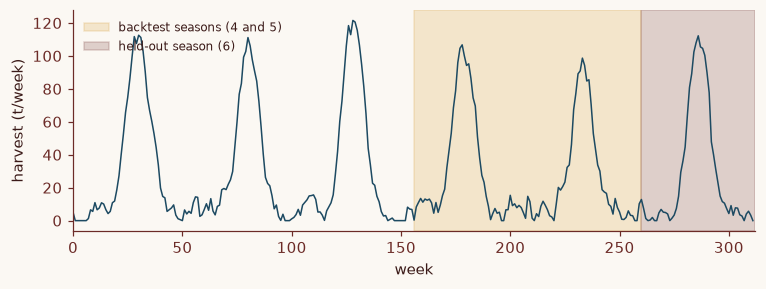

In [2]:
def simulate(seed, seasons=6):
    """Synthetic weekly harvest (t/week): one bell-shaped season per 52 weeks."""
    rng = np.random.default_rng(seed)
    t = np.arange(seasons * P)
    size = rng.normal(100, 20, seasons)  # peak height, varies by season
    peak = rng.normal(26, 2.5, seasons)  # week of peak, varies by season
    shape = np.exp(-0.5 * ((t % P - peak[t // P]) / 5) ** 2)
    noise = np.zeros(len(t))
    for i in range(1, len(t)):  # AR(1): a good week tends to follow a good week
        noise[i] = 0.7 * noise[i - 1] + rng.normal(0, 4)
    return pd.Series(np.clip(5 + size[t // P] * shape + noise, 0, None))


y = simulate(seed=0)

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(y.index, y, color=C1, lw=1)
ax.axvspan(3 * P, 5 * P, color=C2, alpha=0.2, label="backtest seasons (4 and 5)")
ax.axvspan(5 * P, 6 * P, color=C3, alpha=0.2, label="held-out season (6)")
ax.set(xlabel="week", ylabel="harvest (t/week)", xlim=(0, 6 * P))
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

**Figure 1 | The synthetic series.** Six seasons of weekly harvest. Seasons 4 and 5 are used for the backtest, season 6 is held out and touched by nothing until the end.

A rolling-origin backtest steps the origin forward one week at a time. The training set either grows (an **expanding window**) or keeps a fixed length (a **sliding window**), which adapts faster when the process drifts but trains on fewer rows.

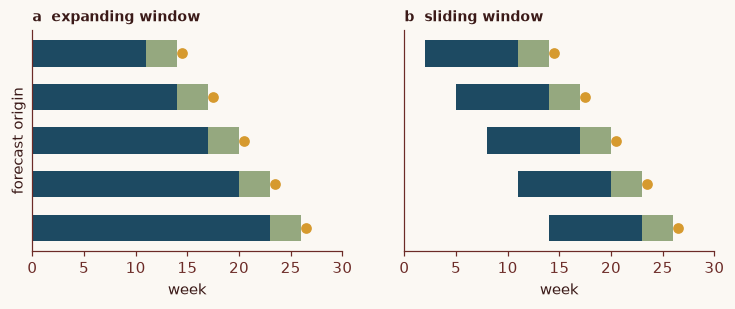

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
h, window = 4, 8
for ax, title, sliding in zip(axes, ["a  expanding window", "b  sliding window"], [False, True]):
    for k in range(5):  # one row per forecast origin
        origin = 10 + 3 * k
        start = origin - window if sliding else 0
        ax.barh(k, origin + 1 - start, left=start, color=C1, height=0.6)  # weeks <= origin
        ax.barh(k, h - 1, left=origin + 1, color=C4, height=0.6)
        ax.plot(origin + h + 0.5, k, "o", color=C2, ms=6)
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold")
    ax.set(xlabel="week", yticks=[], xlim=(0, 30))
axes[0].set_ylabel("forecast origin")
axes[0].invert_yaxis()
plt.show()

**Figure 2 | Two ways to roll the origin.** Each row is one forecast origin, for $h = 4$. The model is fitted on the weeks known at that origin (dark bar) and scored on the week $h$ steps later (dot); the light bar is the weeks in between. **a**, Expanding window. **b**, Sliding window of fixed length.

The model is gradient-boosted trees, one per horizon, fitted to a table with one row per origin $t$. Every feature is indexed from the origin, so it is known at $t$: the last three weeks, and the same week one season before the target.

In [4]:
FEATS = ["y_t", "y_t-1", "y_t-2", "same_week_last_season", "target_week"]


def rows(y, h):
    """One row per origin t: features known at t, target y[t+h]."""
    t = np.arange(len(y))
    d = pd.DataFrame({
        "y_t": y, "y_t-1": y.shift(1), "y_t-2": y.shift(2),
        "same_week_last_season": y.shift(P - h),  # y[t+h-52], known at t
        "target_week": (t + h) % P,
        "target_time": t + h,
        "target": y.shift(-h),
    })
    return d.dropna()


rows(y, h=4).head(3).round(1)

,y_t,y_t-1,y_t-2,same_week_last_season,target_week,target_time,target
48,1.2,3.4,9.5,5.0,0,52,4.1
49,0.6,1.2,3.4,0.0,1,53,5.7
50,0.0,0.6,1.2,0.0,2,54,4.4


The line that matters is the mask `known`: a row with origin $s$ carries the target $y_{s+h}$, which is only observed at week $s+h$. At origin $t$, rows with $s > t - h$ have targets in the future, so they are excluded. That exclusion is the **gap**.

In [5]:
def model():
    return HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=0)


def rolling_origin(d, first, last, refit_every=4, gap=True):
    """Replay the forecast for targets in [first, last), refitting every few weeks."""
    test = d[(d.target_time >= first) & (d.target_time < last)]
    preds = []
    for _, block in test.groupby(np.arange(len(test)) // refit_every):
        origin = block.index[0]  # the week this model is fitted
        if gap:  # only rows whose target had been observed by the origin
            known = d.target_time <= origin
        else:  # the mistake: every row up to the origin, targets and all
            known = d.index <= origin
        fit = model().fit(d.loc[known, FEATS], d.loc[known, "target"])
        preds.append(fit.predict(block[FEATS]))
    return test.assign(pred=np.concatenate(preds))


def shuffled_kfold(d):
    """The usual machine-learning default: 5 random folds."""
    pred = pd.Series(np.nan, index=d.index)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(d):
        fit = model().fit(d.iloc[tr][FEATS], d.iloc[tr]["target"])
        pred.iloc[te] = fit.predict(d.iloc[te][FEATS])
    return d.assign(pred=pred)


def mae(df, col="pred"):
    return (df[col] - df["target"]).abs().mean()

`TimeSeriesSplit` does the same thing when its `gap` is set to $h - 1$ rows, which is easy to get wrong by one. The assertion checks it for $h = 4$:

In [6]:
d = rows(y, h=4)
train, test = list(TimeSeriesSplit(n_splits=10, test_size=4, gap=4 - 1).split(d))[-1]
origin = d.index[test[0]]
assert d.index[train].equals(d.index[d.target_time <= origin])
print(f"origin week {origin}: last training row is origin {d.index[train[-1]]}, "
      f"whose target is week {d.target_time.iloc[train[-1]]}")

origin week 304: last training row is origin 300, whose target is week 304


In Darts, `historical_forecasts(series, start=..., forecast_horizon=8, retrain=4, last_points_only=False)` runs the same replay, and `train_length` makes the window slide. Darts truncates the series at each origin and rebuilds the training rows from what is left, so it gets the gap right by construction. A loop over a precomputed feature table does not, as the last section shows.

## Shuffled folds flatter

Three estimates of the same model's mean absolute error (MAE, in t/week) at each horizon: shuffled 5-fold cross-validation on seasons 1–5, the rolling-origin backtest over seasons 4 and 5, and the error the same rolling procedure actually makes on held-out season 6.

In [7]:
results, backtests = [], {}
for h in range(1, 9):
    d = rows(y, h)
    history = d[d.target_time < 5 * P]  # everything before the held-out season
    bt = rolling_origin(d, 3 * P, 5 * P)
    backtests[h] = bt
    results.append({
        "h": h,
        "shuffled 5-fold": mae(shuffled_kfold(history)),
        "rolling origin": mae(bt),
        "held-out season": mae(rolling_origin(d, 5 * P, 6 * P)),
        "rolling, no gap": mae(rolling_origin(d, 3 * P, 5 * P, gap=False)),
        "naive": mae(bt, "y_t"),
        "seasonal naive": mae(bt, "same_week_last_season"),
    })
results = pd.DataFrame(results).set_index("h")
results.iloc[:, :3].round(1)

,shuffled 5-fold,rolling origin,held-out season
h,,,
1,5.3,5.4,4.5
2,6.5,6.3,6.3
3,8.0,7.9,7.5
4,9.1,9.5,8.8
5,9.3,9.8,10.1
6,9.4,10.2,10.6
7,9.2,10.0,11.3
8,9.6,10.5,11.4


On this one history the three agree at short horizons and part company at long ones. At $h = 8$, shuffled folds report $9.6$, the backtest $10.5$, and the held-out season delivered $11.4$. But one held-out season is one draw of weather, so a single comparison cannot say which estimator is better. Repeating the whole experiment on 40 independently simulated histories can, at three horizons:

In [8]:
mc = []
for seed in range(40):
    y_s = simulate(seed)
    for h in (1, 4, 8):
        d = rows(y_s, h)
        mc.append({
            "seed": seed, "h": h,
            "shuffled 5-fold": mae(shuffled_kfold(d[d.target_time < 5 * P])),
            "rolling origin": mae(rolling_origin(d, 3 * P, 5 * P)),
            "held-out season": mae(rolling_origin(d, 5 * P, 6 * P)),
        })
mc = pd.DataFrame(mc)
summary = mc.groupby("h")[["shuffled 5-fold", "rolling origin", "held-out season"]].mean()
for col in ("shuffled 5-fold", "rolling origin"):
    below = mc[col] < mc["held-out season"]
    summary[f"{col} / truth"] = summary[col] / summary["held-out season"]
    summary[f"share of runs below truth, {col}"] = below.groupby(mc["h"]).mean()
summary.round(2).T

h,1,4,8
shuffled 5-fold,5.09,8.68,10.43
rolling origin,6.02,11.69,14.36
held-out season,4.98,10.04,13.04
shuffled 5-fold / truth,1.02,0.86,0.80
"share of runs below truth, shuffled 5-fold",0.32,0.48,0.68
rolling origin / truth,1.21,1.16,1.10
"share of runs below truth, rolling origin",0.20,0.30,0.35


Averaged over the 40 histories, shuffled folds are about right at $h = 1$ (ratio to the held-out error $1.02$) and increasingly optimistic as the horizon grows: $0.86$ at $h = 4$ and $0.80$ at $h = 8$, below the truth in $68\%$ of histories at that horizon. The rolling-origin backtest errs the other way, $1.21$, $1.16$ and $1.10$ times the held-out error. A likely reason is that its models are fitted on three to five seasons of history, while the held-out season is forecast by models fitted on five to six. Pessimism of that kind shrinks as history accumulates, and overstating error is usually the safer mistake when the number sets a buffer such as safety stock.

Shuffling flatters because a test week's neighbours on both sides sit in the training folds, with almost the same features and targets from the same season. The trees can look the answer up, which no real forecast can, and the advantage grows with $h$ because the real forecast gets harder while the neighbours stay as close.

Shuffled cross-validation is not always wrong. In an empirical study of model selection on synthetic and real series, Bergmeir and Benítez found no practical consequences of cross-validation's theoretical flaws, and recommended a blocked form as standard[^2]; Bergmeir, Hyndman and Koo showed ordinary $k$-fold is valid for purely autoregressive models whose errors are uncorrelated[^3]. This series breaks that condition: nothing in the features identifies a season's height or timing, so errors stay correlated within a season. [Gradient boosting for tabular time series](../forecast/gradient_boosting_for_time_series.ipynb) shows a trending series where shuffling does far more damage. Backtesting in time order costs little and needs no condition checked.

## Score each horizon against baselines

A single error averaged over horizons hides the shape that decides how a forecast should be used. Score each $h$ separately, and put two baselines beside the model on the same origins: **naive**, which repeats the last observed week, $\hat{y}_{t+h \mid t} = y_t$, and **seasonal naive**, which repeats the same week of the previous season, $\hat{y}_{t+h \mid t} = y_{t+h-52}$.

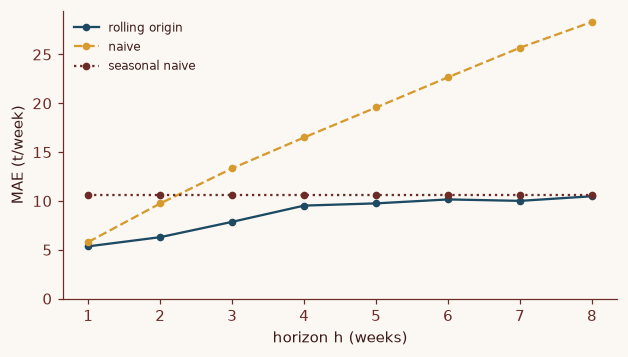

h,1,2,3,4,5,6,7,8,mean over h
rolling origin,5.4,6.3,7.9,9.5,9.8,10.2,10.0,10.5,8.7
naive,5.8,9.7,13.3,16.5,19.6,22.7,25.7,28.3,17.7
seasonal naive,10.6,10.6,10.6,10.6,10.6,10.6,10.6,10.6,10.6


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for col, c, ls in [("rolling origin", C1, "-"), ("naive", C2, "--"), ("seasonal naive", C3, ":")]:
    ax.plot(results.index, results[col], color=c, ls=ls, marker="o", ms=4, label=col)
ax.set(xlabel="horizon h (weeks)", ylabel="MAE (t/week)", ylim=(0, None))
ax.legend(frameon=False, fontsize=8)
plt.show()
scores = results[["rolling origin", "naive", "seasonal naive"]]
scores.T.assign(**{"mean over h": scores.mean()}).round(1)

**Figure 3 | Backtest error by horizon.** Mean absolute error of the gradient-boosted model, the naive forecast and the seasonal-naive forecast, over the same origins in seasons 4 and 5.

Averaged over $h = 1$–$8$, the model's MAE of $8.7$ beats seasonal naive at $10.6$ comfortably. By horizon, the advantage is all in the first few weeks: at $h = 8$ the model scores $10.5$ against $10.6$, adding nothing that last season's curve did not already give. Naive is close to the model at $h = 1$ and useless beyond it. Seasonal naive is flat because it reads the same week of last season whatever the horizon, as long as $h \le 52$. A per-horizon curve against both baselines is also how to compare strategies whose difference is in how error grows with $h$, as in [Direct vs recursive in Darts](../darts-direct-vs-recursive.qmd).

## Gaps, origins and seasons

**The gap.** Rerun the backtest with the mask that keeps every row up to the origin — the natural thing to write when the feature table has already been built — and the model trains on targets up to $h - 1$ weeks into the period it is forecasting:

In [10]:
gap = results[["rolling origin", "rolling, no gap"]].T
gap.loc["understated by"] = 1 - gap.iloc[1] / gap.iloc[0]
gap.round(2)

h,1,2,3,4,5,6,7,8
rolling origin,5.35,6.30,7.86,9.53,9.75,10.16,10.01,10.48
"rolling, no gap",4.60,5.35,6.48,7.56,7.85,8.26,8.37,8.84
understated by,0.14,0.15,0.18,0.21,0.20,0.19,0.16,0.16


Without the gap the error is understated by $14$–$21\%$. No feature leaked; the training labels did. Blocked cross-validation with training blocks after the test block needs the same care on both sides: drop rows whose lags or rolling windows overlap the test block.

**Origins and seasons.** How many origins are enough depends on how much the error moves between them, and on a seasonal series it moves a great deal:

In [11]:
bt = backtests[4]
print("h = 4, MAE by season:", bt.groupby(bt.target_time // P + 1).apply(mae).round(1).to_dict())
quarter = bt.target_week // 13 + 1
print("h = 4, MAE by quarter of the season:", bt.groupby(quarter).apply(mae).round(1).to_dict())
ratio = mc["rolling origin"] / mc["held-out season"]
spread = ratio.groupby(mc["h"]).quantile([0.1, 0.9]).unstack().round(2)
spread.columns = ["10th percentile", "90th percentile"]
spread  # rolling-origin estimate / held-out error, across the 40 histories

h = 4, MAE by season: {4: 7.7, 5: 11.3}
h = 4, MAE by quarter of the season: {1: 4.2, 2: 17.1, 3: 13.0, 4: 3.8}


,10th percentile,90th percentile
h,,
1,0.84,1.81
4,0.81,1.96
8,0.61,2.01


At $h = 4$ the backtest MAE was $7.7$ in season 4 and $11.3$ in season 5. Within a season it was $4.2$ in the first quarter, $17.1$ in the second, $13.0$ in the third and $3.8$ in the fourth. A backtest whose origins fall only in quiet weeks reports the error of quiet weeks. Even two whole seasons leave wide uncertainty: across the 40 histories, the backtest at $h = 4$ ranged from $0.81$ to $1.96$ times the next season's error (10th to 90th percentile). So use every issue week as an origin, cover whole seasons, use as many seasons as the data and any changes in the process allow, and report the season-to-season spread with the average.

## Key takeaways

- A backtest replays the forecast: same horizons, same issue cadence, only the information known at each origin, and the same refit schedule as production.
- On this synthetic seasonal series, shuffled 5-fold cross-validation was increasingly optimistic with horizon, $0.80$ of the held-out error at $h = 8$; a rolling-origin backtest was $1.10$ of it.
- When slicing a precomputed feature table, keep only rows whose target was observed by the origin: a gap of $h - 1$ rows in `TimeSeriesSplit`. Dropping it understated the error by $14$–$21\%$ here.
- Score each horizon separately and beside naive and seasonal-naive baselines. An average over horizons hid that the model added nothing over seasonal naive at $h = 8$.
- Cover whole seasons with origins at every issue week. Here the error ran from $3.8$ to $17.1$ between quarters of one season, and from $7.7$ to $11.3$ between two seasons.

## References

[^1]: Tashman, L. J. Out-of-sample tests of forecasting accuracy: an analysis and review. *Int. J. Forecast.* **16**, 437–450 (2000). https://doi.org/10.1016/S0169-2070(00)00065-0
[^2]: Bergmeir, C. & Benítez, J. M. On the use of cross-validation for time series predictor evaluation. *Inf. Sci.* **191**, 192–213 (2012). https://doi.org/10.1016/j.ins.2011.12.028
[^3]: Bergmeir, C., Hyndman, R. J. & Koo, B. A note on the validity of cross-validation for evaluating autoregressive time series prediction. *Comput. Stat. Data Anal.* **120**, 70–83 (2018). https://doi.org/10.1016/j.csda.2017.11.003

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/leakage/leakage.html"><span>Previous</span>Leakage</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/forecast/1_feature_engineering.html"><span>Next</span>Feature engineering with feature_engine</a></div>
<!-- CURRICULUM_FOOTER_END -->